# 01 · Exploratory analysis

**Data-driven:** the notebook first takes an inventory of whatever is in `data/raw/`, recognises Home Credit tables by
their columns (whatever the files are called), and adapts. The application table drives sections 1–7. Any related
tables you add (bureau, previous applications, instalments, POS/cash, credit cards) are analysed automatically in
section 8. Re-run the notebook after adding data.

Only aggregate statistics are shown; no individual records are printed. Analysis uses the **training split only**,
so the test split stays untouched for model validation.

**Questions:** What data do we have? How imbalanced is the target? How complete is the data? Which variables
separate defaulters from non-defaulters? Are there data-quality issues to handle? Do related tables add signal?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import pyarrow.parquet as pq
from IPython.display import display
from sklearn.metrics import roc_auc_score
from credit_risk import PROJECT_ROOT, load_config, project_path
from credit_risk.ingestion import make_splits

sns.set_theme(style="whitegrid", palette="deep"); pd.set_option("display.float_format", "{:.4f}".format)
cfg = load_config(); TARGET, ID = cfg["data"]["target"], cfg["data"]["id_col"]
RAW_DIR = project_path(cfg["data"]["raw_path"]).parent

## 0. Data inventory

Every CSV/parquet file in `data/raw/` is profiled and matched to a Home Credit table by its **signature columns**.
The application table (one row per loan, with `TARGET`) is required. The others are optional and join on `SK_ID_CURR`
(or `SK_ID_BUREAU` for bureau balances).

In [2]:
# Signature columns that identify each Home Credit table, whatever the file is called.
# Each signature contains at least one column unique to that table, so tables that share columns are not confused.
TABLES = {
    "application":           ({"SK_ID_CURR", "TARGET", "AMT_CREDIT"}, "loan applications with the default flag (required)"),
    "bureau":                ({"SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE"}, "credits at other lenders, reported to the credit bureau"),
    "bureau_balance":        ({"SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"}, "monthly status (days past due) of those bureau credits"),
    "previous_application":  ({"SK_ID_CURR", "SK_ID_PREV", "AMT_APPLICATION"}, "earlier applications at this lender (approved / refused)"),
    "pos_cash_balance":      ({"SK_ID_PREV", "CNT_INSTALMENT_FUTURE", "SK_DPD"}, "monthly balances of previous POS and cash loans"),
    "installments_payments": ({"SK_ID_PREV", "DAYS_INSTALMENT", "AMT_PAYMENT"}, "repayment history on previous loans"),
    "credit_card_balance":   ({"SK_ID_PREV", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL"}, "monthly balances of previous credit cards"),
}


def header(path):
    return pq.read_schema(path).names if path.suffix == ".parquet" else pd.read_csv(path, nrows=0).columns.tolist()


def n_rows(path):
    if path.suffix == ".parquet":
        return pq.ParquetFile(path).metadata.num_rows
    with open(path, "rb") as f:
        return sum(1 for _ in f) - 1


def identify(columns):
    cols = set(columns)
    return next((name for name, (sig, _) in TABLES.items() if sig <= cols), "unrecognised")


def inventory(raw_dir):
    rows = []
    for p in sorted(raw_dir.glob("*")):
        if p.suffix not in (".csv", ".parquet"):
            continue
        cols = header(p)
        sample = pd.read_parquet(p).head(50_000) if p.suffix == ".parquet" else pd.read_csv(p, nrows=50_000)
        rows.append({"file": p.name, "table": identify(cols), "rows": n_rows(p), "columns": len(cols),
                     "size_mb": p.stat().st_size / 1e6, "missing_cells": sample.isna().mean().mean(),
                     "keys": ", ".join(k for k in ("SK_ID_CURR", "SK_ID_PREV", "SK_ID_BUREAU") if k in cols),
                     "has_target": TARGET in cols})
    return pd.DataFrame(rows, columns=["file", "table", "rows", "columns", "size_mb", "missing_cells", "keys", "has_target"])


inv = inventory(RAW_DIR)
AVAILABLE = {r.table: RAW_DIR / r.file for r in inv.itertuples() if r.table != "unrecognised"}
shown = RAW_DIR.relative_to(PROJECT_ROOT) if RAW_DIR.is_relative_to(PROJECT_ROOT) else RAW_DIR
print(f"{len(inv)} data file(s) in {shown}/")
display(inv.style.format({"rows": "{:,}", "size_mb": "{:,.1f}", "missing_cells": "{:.1%}"}).hide(axis="index"))

status = pd.DataFrame([{"table": t, "available": "✅ " + AVAILABLE[t].name if t in AVAILABLE else "—", "adds": desc}
                       for t, (_, desc) in TABLES.items()])
display(status.style.hide(axis="index"))

1 data file(s) in data/raw/


file,table,rows,columns,size_mb,missing_cells,keys,has_target
HomeLoanData.csv,application,"307,511",122,148.7,24.4%,SK_ID_CURR,True


table,available,adds
application,✅ HomeLoanData.csv,loan applications with the default flag (required)
bureau,—,"credits at other lenders, reported to the credit bureau"
bureau_balance,—,monthly status (days past due) of those bureau credits
previous_application,—,earlier applications at this lender (approved / refused)
pos_cash_balance,—,monthly balances of previous POS and cash loans
installments_payments,—,repayment history on previous loans
credit_card_balance,—,monthly balances of previous credit cards


In [3]:
assert "application" in AVAILABLE, (
    f"No application table found in {RAW_DIR}. Add the Home Credit application_train file "
    "(e.g. as HomeLoanData.csv) – see docs/data_dictionary.md.")
cfg_raw = project_path(cfg["data"]["raw_path"])
if cfg_raw != AVAILABLE["application"]:
    print(f"⚠️  Application data detected in {AVAILABLE['application'].name}, but configs/model_config.yaml → "
          f"data.raw_path points to {cfg_raw.name}. Splits are built from the config path. Update it if needed.")

splits = make_splits(cfg)
train = splits.train  # analysis on the training split only: the test split stays untouched
print(f"Application table → train {len(train):,} | val {len(splits.val):,} | test {len(splits.test):,} | "
      f"columns {train.shape[1]}")
print(f"Related tables available: {sorted(t for t in AVAILABLE if t != 'application') or 'none (section 8 will list what each would add)'}")

Application table → train 196,806 | val 49,202 | test 61,503 | columns 122
Related tables available: none (section 8 will list what each would add)


## 1. Target

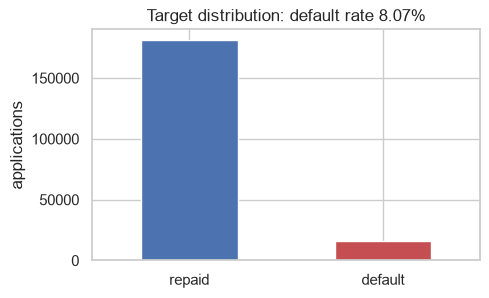

Imbalance ratio ≈ 1:11.4  → use ranking metrics (AUC/Gini/KS) and check calibration, not accuracy


In [4]:
rate = train[TARGET].mean()
fig, ax = plt.subplots(figsize=(5, 3))
train[TARGET].value_counts().sort_index().rename({0: "repaid", 1: "default"}).plot.bar(ax=ax, color=["#4c72b0", "#c44e52"])
ax.set(title=f"Target distribution: default rate {rate:.2%}", ylabel="applications", xlabel=""); plt.xticks(rotation=0); plt.show()
print(f"Imbalance ratio ≈ 1:{(1 - rate) / rate:.1f}  → use ranking metrics (AUC/Gini/KS) and check calibration, not accuracy")

## 2. Data types and completeness

float64    104
object      16
int64        2

Columns with any missing: 67 of 122 · >50% missing: 41


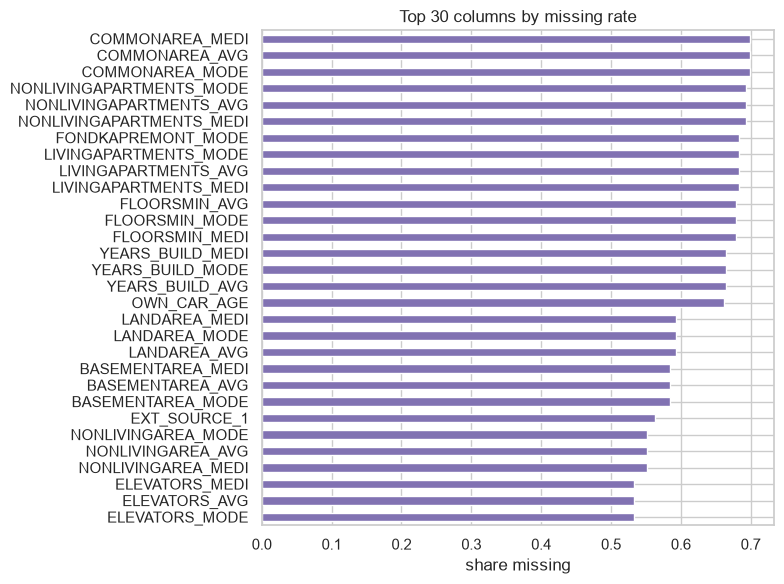

In [5]:
dtypes = train.dtypes.astype(str).replace({"str": "object"}).value_counts()
print(dtypes.to_string())
miss = train.isna().mean().sort_values(ascending=False)
print(f"\nColumns with any missing: {(miss > 0).sum()} of {len(miss)} · >50% missing: {(miss > 0.5).sum()}")
fig, ax = plt.subplots(figsize=(8, 6))
miss.head(30).iloc[::-1].plot.barh(ax=ax, color="#8172b2"); ax.set(title="Top 30 columns by missing rate", xlabel="share missing")
plt.tight_layout(); plt.show()

In [6]:
building = [c for c in train if c.endswith(("_AVG", "_MODE", "_MEDI"))]
print(f"{len(building)} building/housing descriptors (_AVG/_MODE/_MEDI): median missing {train[building].isna().mean().median():.0%}")
has_building = train[building].notna().any(axis=1)
print("Default rate when building info present vs absent:",
      f"{train.loc[has_building, TARGET].mean():.2%} vs {train.loc[~has_building, TARGET].mean():.2%}")

47 building/housing descriptors (_AVG/_MODE/_MEDI): median missing 55%
Default rate when building info present vs absent: 7.02% vs 9.24%


Missingness is **informative**: applicants without housing details default more often. Tree models handle NaNs natively after median imputation plus engineered null counts, so nothing is dropped up front.

## 3. Data-quality checks

In [7]:
emp_anom = (train["DAYS_EMPLOYED"] == 365243)
print(f"DAYS_EMPLOYED == 365243 (sentinel for 'not employed'): {emp_anom.mean():.1%} of rows; "
      f"default rate {train.loc[emp_anom, TARGET].mean():.2%} vs {train.loc[~emp_anom, TARGET].mean():.2%} otherwise")
print(f"Income: median {train.AMT_INCOME_TOTAL.median():,.0f}, 99.9th pct {train.AMT_INCOME_TOTAL.quantile(.999):,.0f}, max {train.AMT_INCOME_TOTAL.max():,.0f}")
print(f"Duplicate application IDs: {train[cfg['data']['id_col']].duplicated().sum()}")
from credit_risk.validation import validate_applications
rep = validate_applications(train, target=TARGET, id_col=cfg["data"]["id_col"])
print("Validation:", "OK" if rep.ok else rep.errors, "| warnings:", rep.warnings)

DAYS_EMPLOYED == 365243 (sentinel for 'not employed'): 18.0% of rows; default rate 5.34% vs 8.67% otherwise
Income: median 148,500, 99.9th pct 900,000, max 18,000,090
Duplicate application IDs: 0


Validation: OK | warnings: []


## 4. Key numeric drivers

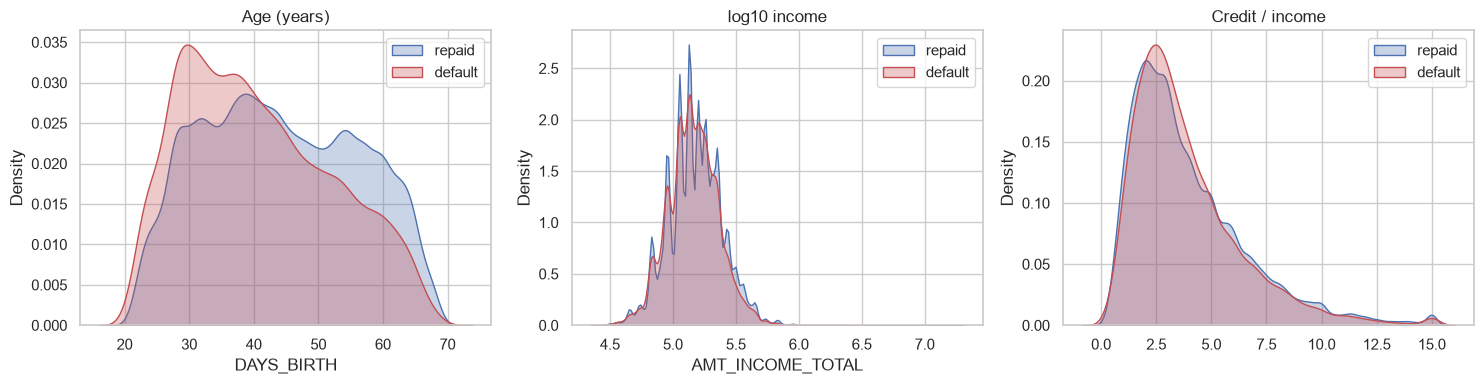

In [8]:
age = -train["DAYS_BIRTH"] / 365.25
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, s) in zip(axes, {"Age (years)": age, "log10 income": np.log10(train.AMT_INCOME_TOTAL),
                                 "Credit / income": (train.AMT_CREDIT / train.AMT_INCOME_TOTAL).clip(upper=15)}.items()):
    for t, col in ((0, "#4c72b0"), (1, "#c44e52")):
        sns.kdeplot(s[train[TARGET] == t], ax=ax, fill=True, alpha=.3, color=col, label="default" if t else "repaid", common_norm=False)
    ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

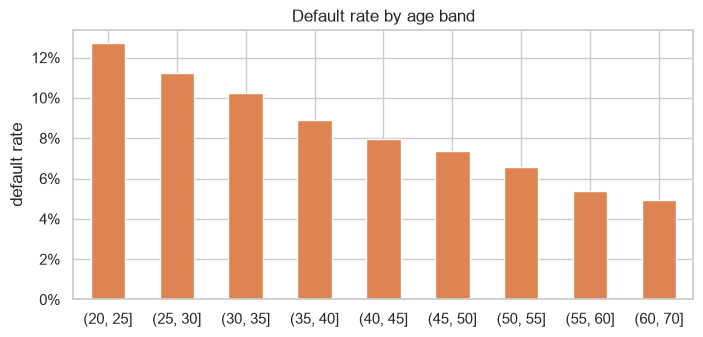

In [9]:
bands = pd.cut(age, [20, 25, 30, 35, 40, 45, 50, 55, 60, 70])
ax = train.groupby(bands, observed=True)[TARGET].mean().plot.bar(figsize=(8, 3.5), color="#dd8452")
ax.set(title="Default rate by age band", ylabel="default rate", xlabel=""); ax.yaxis.set_major_formatter("{x:.0%}"); plt.xticks(rotation=0); plt.show()

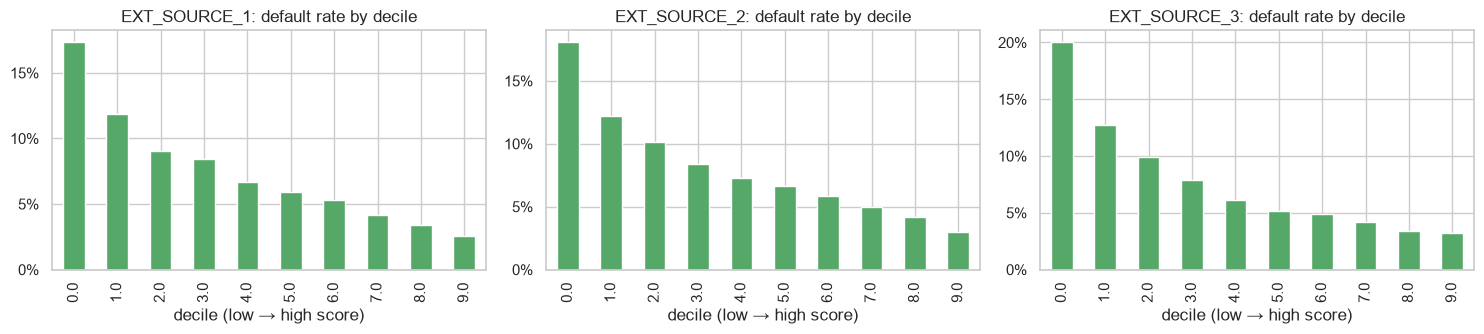

              EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  TARGET
EXT_SOURCE_1        1.0000        0.2120        0.1900 -0.1560
EXT_SOURCE_2        0.2120        1.0000        0.1080 -0.1590
EXT_SOURCE_3        0.1900        0.1080        1.0000 -0.1800
TARGET             -0.1560       -0.1590       -0.1800  1.0000


In [10]:
ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, c in zip(axes, ext):
    dec = pd.qcut(train[c], 10, labels=False, duplicates="drop")
    train.groupby(dec)[TARGET].mean().plot.bar(ax=ax, color="#55a868"); ax.set(title=f"{c}: default rate by decile", xlabel="decile (low → high score)")
    ax.yaxis.set_major_formatter("{x:.0%}")
plt.tight_layout(); plt.show()
print(train[ext + [TARGET]].corr().round(3).to_string())

## 5. Categorical drivers

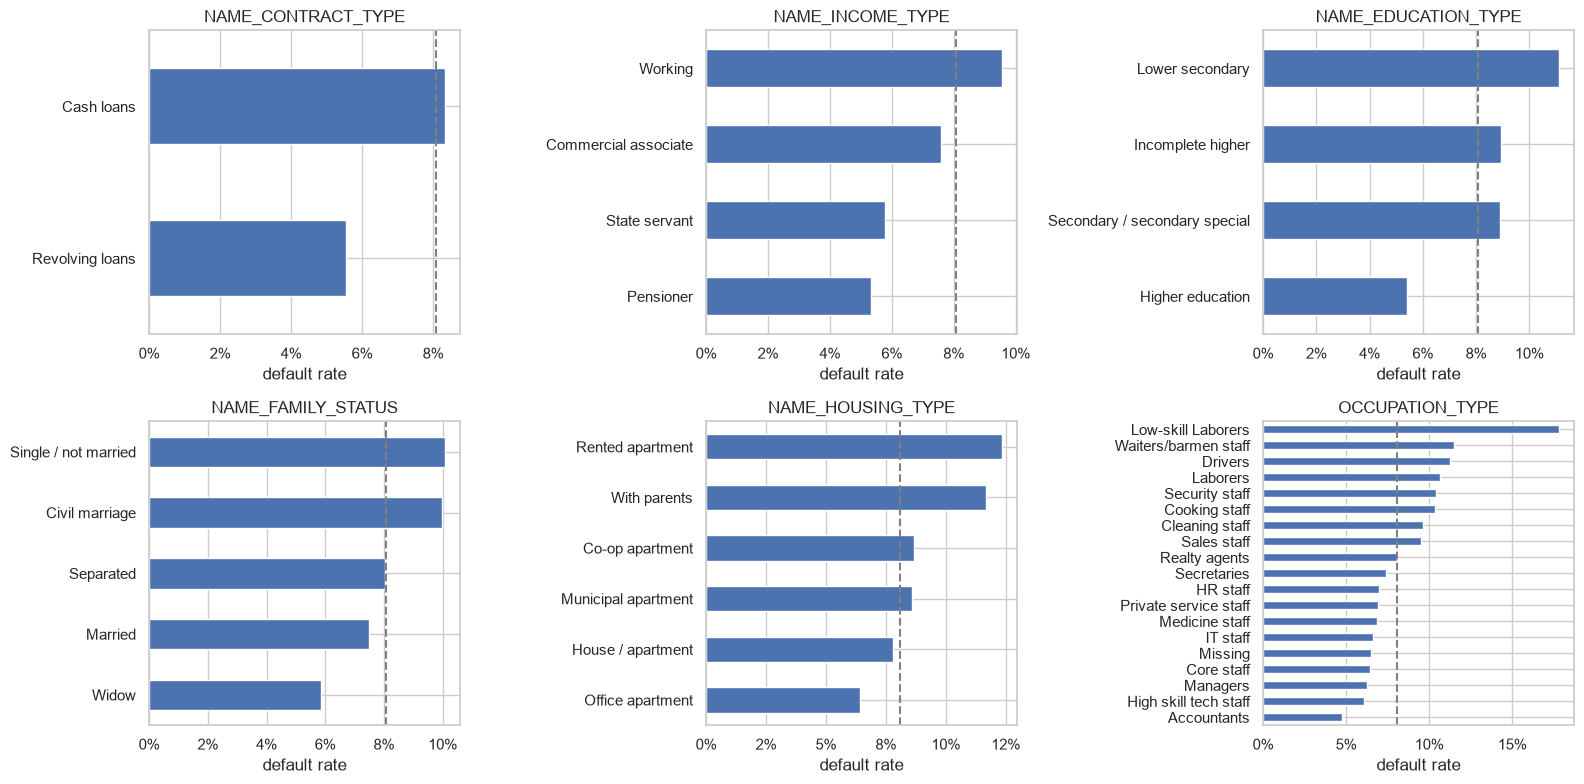

In [11]:
cats = ["NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cats):
    g = train.assign(**{c: train[c].fillna("Missing")}).groupby(c)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= 200].sort_values("mean")
    g["mean"].plot.barh(ax=ax, color="#4c72b0"); ax.set(title=c, xlabel="default rate", ylabel="")
    ax.xaxis.set_major_formatter("{x:.0%}"); ax.axvline(rate, ls="--", c="grey")
plt.tight_layout(); plt.show()

## 6. Univariate predictive power

Gini of each numeric variable on its own (|2·AUC − 1|). This is a quick screen; it does not capture interactions.

In [12]:
def univariate_gini(df, cols):
    out = []
    for c in cols:
        s = df[c]
        if s.notna().sum() < 1000 or s.nunique() < 2:
            continue
        auc = roc_auc_score(df.loc[s.notna(), TARGET], s.dropna())
        out.append({"feature": c, "gini": abs(2 * auc - 1), "direction": "+" if auc > 0.5 else "-",
                    "missing": s.isna().mean()})
    return pd.DataFrame(out).sort_values("gini", ascending=False, ignore_index=True)

In [13]:
num_cols = [c for c in train.select_dtypes("number").columns if c not in (TARGET, cfg["data"]["id_col"])]
ug = univariate_gini(train, num_cols)
ug.head(20)

,feature,gini,direction,missing
0,EXT_SOURCE_3,0.3619,-,0.1982
1,EXT_SOURCE_1,0.3347,-,0.5629
2,EXT_SOURCE_2,0.3098,-,0.0021
3,DAYS_BIRTH,0.1715,+,0.0000
4,OWN_CAR_AGE,0.1197,+,0.6611
5,DAYS_LAST_PHONE_CHANGE,0.1124,+,0.0000
6,DAYS_ID_PUBLISH,0.1095,+,0.0000
7,FLOORSMAX_AVG,0.1046,-,0.4970
8,FLOORSMAX_MEDI,0.1045,-,0.4970
9,FLOORSMAX_MODE,0.1021,-,0.4970


## 7. Protected attributes

`CODE_GENDER` is excluded from modelling (`configs/model_config.yaml → exclude_features`). It is kept in the data only so that fairness can be monitored.

In [14]:
train.groupby("CODE_GENDER")[TARGET].agg(default_rate="mean", applications="size")

,default_rate,applications
CODE_GENDER,,
F,0.0701,129571
M,0.1013,67234
XNA,0.0000,1


## 8. Related tables (auto-detected)

For each related table found in section 0, this section reports:
- **coverage**: the share of training applicants with at least one record, and records per applicant
- **default rate by number of records** (having history at all is often a signal)
- **behavioural signals** that are standard in credit risk: bureau overdues and active credits, previous refusals,
  late or short instalment payments, POS/cash days past due, card utilisation, bureau DPD history

Tables that are not available are skipped. Add the files to `data/raw/` and re-run the notebook to include them.

In [15]:
base = train[[ID, TARGET]]


def load(table, cols):
    p = AVAILABLE[table]
    return pd.read_parquet(p, columns=cols) if p.suffix == ".parquet" else pd.read_csv(p, usecols=cols)


def by_flag(flag, signal):
    """Default rate of training applicants for whom `flag` is yes / no, or who have no records in the table."""
    m = base.join(flag.rename("flag"), on=ID)
    m["group"] = np.where(m["flag"].isna(), "no records", np.where(m["flag"].fillna(False).astype(bool), "yes", "no"))
    out = m.groupby("group")[TARGET].agg(default_rate="mean", applicants="size").reset_index()
    return out.assign(signal=signal)[["signal", "group", "applicants", "default_rate"]]


def coverage(table, d):
    n = d.groupby(ID).size()
    m = base.join(n.rename("n"), on=ID).fillna({"n": 0})
    band = pd.cut(m["n"], [-1, 0, 1, 3, 7, np.inf], labels=["0", "1", "2–3", "4–7", "8+"])
    summary = {"table": table, "rows (train applicants)": len(d), "applicants covered": (m["n"] > 0).mean(),
               "median records per covered applicant": m.loc[m["n"] > 0, "n"].median()}
    return summary, m.groupby(band, observed=True)[TARGET].mean()


# table -> (columns to load, per-applicant boolean signals)
SIGNALS = {
    "bureau": (["SK_ID_CURR", "CREDIT_ACTIVE", "CREDIT_DAY_OVERDUE"], lambda d: {
        "has an active bureau credit": (d["CREDIT_ACTIVE"] == "Active").groupby(d[ID]).any(),
        "currently overdue at the bureau": d.groupby(ID)["CREDIT_DAY_OVERDUE"].max() > 0}),
    "previous_application": (["SK_ID_CURR", "NAME_CONTRACT_STATUS"], lambda d: {
        "a previous application was refused": (d["NAME_CONTRACT_STATUS"] == "Refused").groupby(d[ID]).any()}),
    "installments_payments": (["SK_ID_CURR", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"], lambda d: {
        "ever paid an instalment late": (d["DAYS_ENTRY_PAYMENT"] > d["DAYS_INSTALMENT"]).groupby(d[ID]).any(),
        "ever under-paid an instalment": (d["AMT_PAYMENT"] < d["AMT_INSTALMENT"] - 1).groupby(d[ID]).any()}),
    "pos_cash_balance": (["SK_ID_CURR", "SK_DPD"], lambda d: {
        "any days past due on POS/cash loans": d.groupby(ID)["SK_DPD"].max() > 0}),
    "credit_card_balance": (["SK_ID_CURR", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL"], lambda d: {
        "average card utilisation above 80%":
            (d["AMT_BALANCE"] / d["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)).groupby(d[ID]).mean() > 0.8}),
}

related = [t for t in SIGNALS if t in AVAILABLE]
if not related:
    print("Only the application table is available, so there is no related-table analysis yet.\n"
          "Adding any of these to data/raw/ (from the Home Credit Default Risk download) would extend the analysis:")
    for t, (_, desc) in TABLES.items():
        if t not in AVAILABLE:
            print(f"  • {t:<22} {desc}")
else:
    summaries, signals, bands = [], [], {}
    for t in related:
        cols, make_signals = SIGNALS[t]
        d = load(t, cols)
        d = d[d[ID].isin(base[ID])]                    # training applicants only
        s, bands[t] = coverage(t, d)
        summaries.append(s)
        signals += [by_flag(flag, label) for label, flag in make_signals(d).items()]

    if {"bureau", "bureau_balance"} <= set(AVAILABLE):  # bureau balances join via SK_ID_BUREAU
        bb = load("bureau_balance", ["SK_ID_BUREAU", "STATUS"])
        late = bb["STATUS"].astype(str).isin(list("12345")).groupby(bb["SK_ID_BUREAU"]).any()
        bmap = load("bureau", ["SK_ID_BUREAU", ID])
        flag = bmap.join(late.rename("late"), on="SK_ID_BUREAU").groupby(ID)["late"].any()
        signals.append(by_flag(flag, "ever days-past-due in bureau history"))

    display(pd.DataFrame(summaries).style.format({"applicants covered": "{:.1%}", "rows (train applicants)": "{:,}"})
            .hide(axis="index"))
    display(pd.concat(signals, ignore_index=True).style.format({"default_rate": "{:.2%}", "applicants": "{:,}"})
            .hide(axis="index"))

    fig, axes = plt.subplots(1, len(bands), figsize=(4.5 * len(bands), 3.5), squeeze=False)
    for ax, (t, b) in zip(axes[0], bands.items()):
        b.plot.bar(ax=ax, color="#4c72b0"); ax.axhline(base[TARGET].mean(), ls="--", c="grey")
        ax.set(title=t, xlabel="records per applicant", ylabel="default rate"); ax.yaxis.set_major_formatter("{x:.0%}")
        ax.tick_params(axis="x", rotation=0)
    plt.tight_layout(); plt.show()

Only the application table is available, so there is no related-table analysis yet.
Adding any of these to data/raw/ (from the Home Credit Default Risk download) would extend the analysis:
  • bureau                 credits at other lenders, reported to the credit bureau
  • bureau_balance         monthly status (days past due) of those bureau credits
  • previous_application   earlier applications at this lender (approved / refused)
  • pos_cash_balance       monthly balances of previous POS and cash loans
  • installments_payments  repayment history on previous loans
  • credit_card_balance    monthly balances of previous credit cards


## Findings

0. **Data available:** the application table only (307,511 loans × 122 columns). Section 8 lists the related tables that
   could be added. Repayment-behaviour tables (bureau, instalments, previous applications) typically add substantial
   signal beyond application data, so they are the main lever for improving the model. *Update this list after re-running with new data.*
1. **Imbalanced target (~8% default)**, so evaluate with AUC/Gini/KS and calibration, not accuracy.
2. **External bureau scores (`EXT_SOURCE_1–3`) are by far the strongest signals**, with a clean monotonic relationship.
   Missing values in them are common, so null counts and min/mean/max combinations are worth engineering.
3. **Age and employment matter.** Younger applicants and short tenure default more often. `DAYS_EMPLOYED = 365243` is a
   sentinel (18% of rows, virtually all pensioners) with a *lower* default rate (5.3% vs 8.7%), so it must be flagged
   rather than treated as a number.
4. **Loan size and income alone are weak predictors.** Ratios describing the loan's structure are tested in notebook 02.
5. **Missingness is informative** (housing descriptors), so keep NaNs and let the model use them.
6. **Gender shows a different default rate**, which is exactly why it is excluded and monitored for proxy effects.

→ Next: `02_feature_engineering.ipynb`